<a href="https://colab.research.google.com/github/rahul18107/deep-learning/blob/main/1BM24CD054_S_Rahul_Program_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving new.jpg to new.jpg


In [ ]:
image_path = "new.jpg"
result_image = detect_objects_with_boxes(image_path, detector)

bus: 0.80
car: 0.79
car: 0.76
car: 0.71
car: 0.69
car: 0.65
person: 0.60
Total objects detected: 7


Loading object detection model...


Model loaded successfully.
bus: 0.80
car: 0.79
car: 0.76
car: 0.71
car: 0.69
car: 0.65
person: 0.60
Total objects detected: 7
Displaying detected objects...


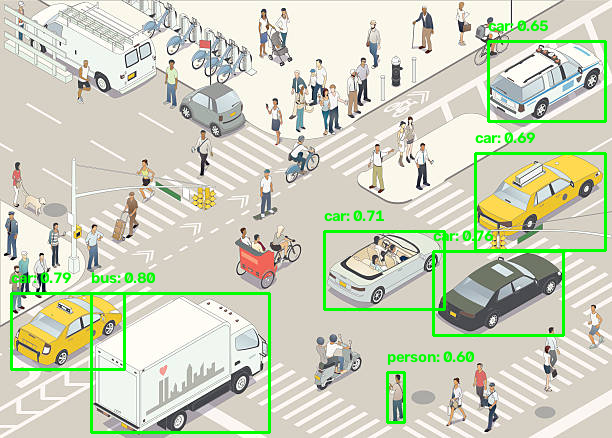

In [ ]:

import tensorflow_hub as hub
import tensorflow as tf
import numpy as np
import cv2
import os
from google.colab import files
from google.colab.patches import cv2_imshow

MODEL_URL = "https://tfhub.dev/tensorflow/efficientdet/d0/1"

print("Loading object detection model...")
detector = hub.load(MODEL_URL)
print("Model loaded successfully.")

COCO_CLASSES = [
    "person", "bicycle", "car", "motorcycle", "airplane", "bus",
    "train", "truck", "boat", "traffic light", "fire hydrant",
    "stop sign", "parking meter", "bench", "bird", "cat", "dog",
    "horse", "sheep", "cow", "elephant", "bear", "zebra",
    "giraffe", "backpack", "umbrella", "handbag", "tie",
    "suitcase", "frisbee", "skis", "snowboard", "sports ball",
    "kite", "baseball bat", "baseball glove", "skateboard",
    "surfboard", "tennis racket", "bottle", "wine glass", "cup",
    "fork", "knife", "spoon", "bowl", "banana", "apple",
    "sandwich", "orange", "broccoli", "carrot", "hot dog",
    "pizza", "donut", "cake", "chair", "couch", "potted plant",
    "bed", "dining table", "toilet", "TV", "laptop", "mouse",
    "remote", "keyboard", "cell phone", "microwave", "oven",
    "toaster", "sink", "refrigerator", "book", "clock", "vase",
    "scissors", "teddy bear", "hair drier", "toothbrush"
]


def detect_objects_with_boxes(image_path, detector):
    image = cv2.imread(image_path)

    if image is None:
        raise FileNotFoundError(
            f"Could not load image. Check the path: {image_path}"
        )

    orig_image = image.copy()
    rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    input_tensor = tf.convert_to_tensor(rgb_image, dtype=tf.uint8)
    input_tensor = input_tensor[tf.newaxis, ...]

    detections = detector(input_tensor)

    num_detections = int(detections["num_detections"].numpy()[0])
    detection_boxes = detections["detection_boxes"].numpy()[0]
    detection_classes = (
        detections["detection_classes"].numpy()[0].astype(np.int32)
    )
    detection_scores = detections["detection_scores"].numpy()[0]

    height, width = orig_image.shape[:2]
    confidence_threshold = 0.5
    detected_count = 0

    for i in range(num_detections):
        score = float(detection_scores[i])

        if score < confidence_threshold:
            continue

        y_min, x_min, y_max, x_max = detection_boxes[i]

        x_min = max(0, min(int(x_min * width), width - 1))
        x_max = max(0, min(int(x_max * width), width - 1))
        y_min = max(0, min(int(y_min * height), height - 1))
        y_max = max(0, min(int(y_max * height), height - 1))

        if x_max <= x_min or y_max <= y_min:
            continue

        class_id = detection_classes[i]

        if 1 <= class_id <= len(COCO_CLASSES):
            class_name = COCO_CLASSES[class_id - 1]
        else:
            class_name = "Unknown"

        label = f"{class_name}: {score:.2f}"

        cv2.rectangle(
            orig_image,
            (x_min, y_min),
            (x_max, y_max),
            (0, 255, 0),
            2
        )

        text_y = max(y_min - 10, 20)

        cv2.putText(
            orig_image,
            label,
            (x_min, text_y),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 255, 0),
            2
        )

        print(label)
        detected_count += 1

    print(f"Total objects detected: {detected_count}")
    return orig_image


image_path = "new.jpg"

if not os.path.exists(image_path):
    print("Upload the image you want to detect objects in:")
    uploaded = files.upload()

    if not uploaded:
        raise ValueError("No image was uploaded.")

    image_path = next(iter(uploaded))

result_image = detect_objects_with_boxes(image_path, detector)

print("Displaying detected objects...")
cv2_imshow(result_image)


In [ ]:

!pip install -q opencv-contrib-python-headless


In [ ]:

import sys
import subprocess

print("Python:", sys.version)

subprocess.run([
    sys.executable, "-m", "pip", "install",
    "--no-cache-dir", "--force-reinstall",
    "opencv-contrib-python-headless"
], check=True)

print("Installation finished.")
print("Now restart the Colab session before continuing.")


Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Installation finished.
Now restart the Colab session before continuing.


In [ ]:

import cv2

print("OpenCV version:", cv2.__version__)
print("OpenCV location:", cv2.__file__)
print("Has ximgproc:", hasattr(cv2, "ximgproc"))

if hasattr(cv2, "ximgproc"):
    print(
        "Has segmentation:",
        hasattr(cv2.ximgproc, "segmentation")
    )

    if hasattr(cv2.ximgproc, "segmentation"):
        search = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
        print("SUCCESS: Selective Search is available.")
    else:
        print("Selective Search module is missing.")
else:
    print("OpenCV contrib is not loaded correctly.")


OpenCV version: 5.0.0
OpenCV location: /usr/local/lib/python3.13/dist-packages/cv2/__init__.py
Has ximgproc: True
Has segmentation: True
SUCCESS: Selective Search is available.


Upload an image:


Saving new.jpg to new (2).jpg


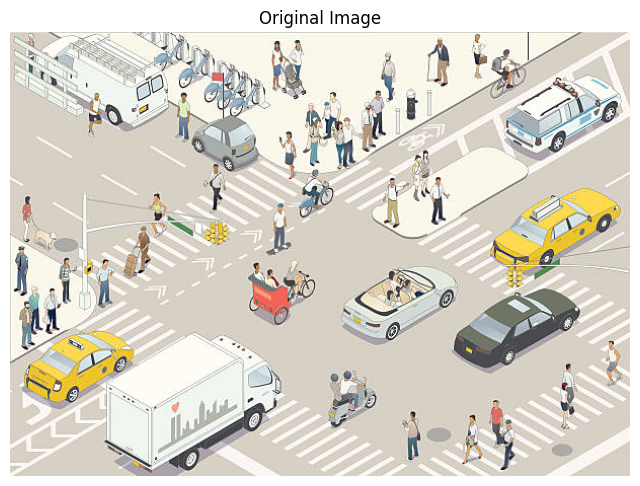

Loading VGG16 model...
553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Model loaded successfully.
Generating region proposals...
Proposals selected: 100
Classifying regions...
4/4 ━━━━━━━━━━━━━━━━━━━━ 36s 9s/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Regions above threshold: 11
bolo_tie: 0.37
matchstick: 0.55
letter_opener: 0.43
folding_chair: 0.40
cleaver: 0.37
modem: 0.35
plate_rack: 0.32
ski: 0.51
parallel_bars: 0.75
parallel_bars: 0.73
parallel_bars: 0.67


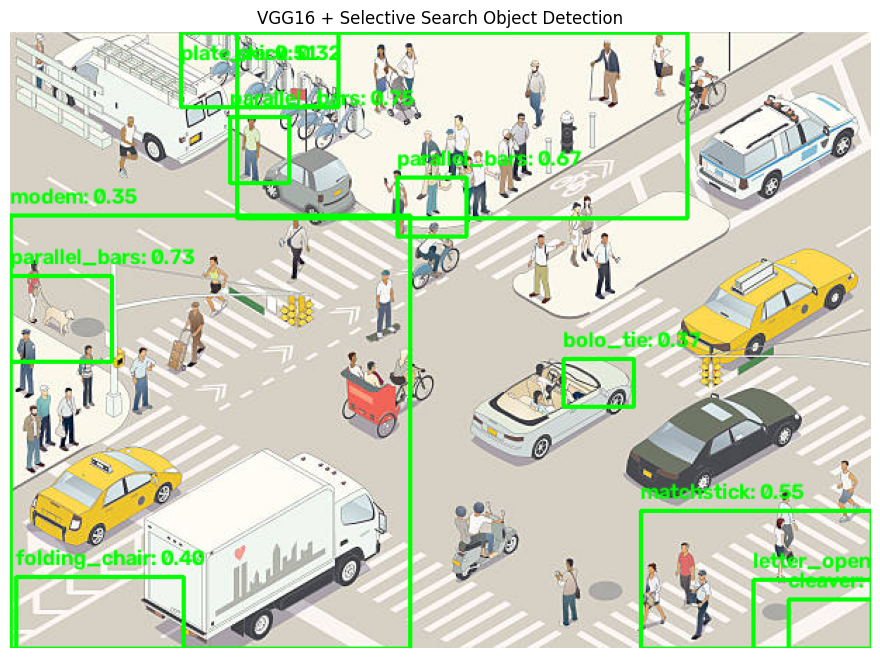

In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import files
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import (
    preprocess_input,
    decode_predictions
)

# Upload image
print("Upload an image:")
uploaded = files.upload()

if not uploaded:
    raise ValueError("No image uploaded.")

image_path = next(iter(uploaded))
image = cv2.imread(image_path)

if image is None:
    raise ValueError("Unable to read the uploaded image.")

# Display original image
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 6))
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

# Check Selective Search availability
if not hasattr(cv2, "ximgproc") or not hasattr(
    cv2.ximgproc, "segmentation"
):
    raise RuntimeError(
        "Selective Search is unavailable. Restart the runtime "
        "after installing opencv-contrib-python-headless."
    )

# Load pretrained VGG16
print("Loading VGG16 model...")
model = VGG16(weights="imagenet", include_top=True)
print("Model loaded successfully.")

# Generate region proposals
print("Generating region proposals...")

selective_search = (
    cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
)
selective_search.setBaseImage(image)
selective_search.switchToSelectiveSearchFast()

rectangles = selective_search.process()

# Limit proposals for faster Colab execution
rectangles = rectangles[:100]
print("Proposals selected:", len(rectangles))

# Prepare image regions
regions = []
batch_images = []

height, width = image.shape[:2]

for x, y, w, h in rectangles:
    if w < 30 or h < 30:
        continue

    crop = image[y:y+h, x:x+w]

    if crop.size == 0:
        continue

    crop = cv2.resize(crop, (224, 224))
    crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)

    batch_images.append(crop)
    regions.append((x, y, w, h))

if len(batch_images) == 0:
    raise RuntimeError("No valid regions found.")

# VGG16 preprocessing
batch_images = np.array(batch_images, dtype=np.float32)
batch_images = preprocess_input(batch_images)

# Classify regions in batches
print("Classifying regions...")

predictions = model.predict(
    batch_images,
    batch_size=16,
    verbose=1
)

results = []

for i, prediction in enumerate(predictions):
    decoded = decode_predictions(
        prediction[np.newaxis, :],
        top=1
    )[0][0]

    class_id = int(np.argmax(prediction))
    label = decoded[1]
    score = float(decoded[2])

    if score >= 0.30:
        x, y, w, h = regions[i]

        results.append({
            "box": [int(x), int(y), int(w), int(h)],
            "label": label,
            "score": score,
            "class_id": class_id
        })

print("Regions above threshold:", len(results))

# Remove overlapping boxes for each class
final_results = []

for class_id in set(r["class_id"] for r in results):
    class_results = [
        r for r in results if r["class_id"] == class_id
    ]

    boxes = [r["box"] for r in class_results]
    scores = [r["score"] for r in class_results]

    selected = cv2.dnn.NMSBoxes(
        boxes,
        scores,
        score_threshold=0.30,
        nms_threshold=0.35
    )

    if len(selected) > 0:
        for idx in np.array(selected).flatten():
            final_results.append(class_results[int(idx)])

# Draw bounding boxes
result_image = image.copy()

for item in final_results:
    x, y, w, h = item["box"]
    label = item["label"]
    score = item["score"]

    cv2.rectangle(
        result_image,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

    text = f"{label}: {score:.2f}"

    cv2.putText(
        result_image,
        text,
        (x, max(y - 8, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (0, 255, 0),
        2
    )

    print(text)

# Display result in Google Colab
result_rgb = cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(result_rgb)
plt.title("VGG16 + Selective Search Object Detection")
plt.axis("off")
plt.show()
